# Блокнот 02: Дослідження часової циклічності (RQ1)

**Дослідницьке питання (RQ1):**
> *Чи існує стійка добова (нічні vs денні нальоти) та тижнева циклічність повітряних тривог в Україні, і як ці патерни трансформувалися в динаміці з 2022 по 2026 рік? Чи є різниця між днями тижня випадковим шумом, чи вона статистично значуща?*

У цьому блокноті розраховуються:
1. Теплова карта 24x7 (Година доби Europe/Kyiv x День тижня).
2. Непараметричний тест Kruskal-Wallis для порівняння активності за днями тижня.
3. Пост-хок порівняння Манна-Вітні з поправкою Бонферроні на 21 пару.
4. Аналіз еволюції добових кривих за роками (2022–2026).
5. Розподіл тривалості тривог (квантилі $Q_{25}, Q_{50}, Q_{75}, Q_{95}$).

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

parquet_path = Path("../data/processed/alerts_clean_oblast.parquet")
df = pd.read_parquet(parquet_path)
clean_df = df[~df["is_occupied_extreme"]].copy()
print(f"Завантажено {len(clean_df):,} тривог для 24 регулярних областей.")

Завантажено 84,907 тривог для 24 регулярних областей.


## 1. Статистичний тест Крускала-Волліса (Kruskal-Wallis)

In [2]:
days_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
days_ua = ["Понеділок", "Вівторок", "Середа", "Четвер", "П'ятниця", "Субота", "Неділя"]
day_map = dict(zip(days_order, days_ua))

daily_counts = clean_df.groupby(["start_date", "start_day_of_week"]).size().reset_index(name="alert_count")
daily_by_day = [daily_counts[daily_counts["start_day_of_week"] == d]["alert_count"].values for d in days_order]

h_stat, p_val = stats.kruskal(*daily_by_day)
print(f"H-статистика Крускала-Волліса: {h_stat:.4f}")
print(f"p-value: {p_val:.4f}")
if p_val < 0.05:
    print("-> Висновок: Відмінності між днями тижня є СТАТИСТИЧНО ЗНАЧУЩИМИ на рівні alpha=0.05!")
else:
    print("-> Висновок: Відмінності між днями тижня є випадковим шумом.")

H-статистика Крускала-Волліса: 25.5178
p-value: 0.0003
-> Висновок: Відмінності між днями тижня є СТАТИСТИЧНО ЗНАЧУЩИМИ на рівні alpha=0.05!


## 2. Середня та медіанна кількість тривог на добу за днями тижня

In [3]:
day_summary = daily_counts.groupby("start_day_of_week")["alert_count"].agg(["median", "mean", "std"]).reindex(days_order)
day_summary.index = [day_map[d] for d in day_summary.index]
display(day_summary)

,median,mean,std
Понеділок,49.0,51.622318,22.668789
Вівторок,51.0,52.287554,21.008181
Середа,52.0,53.371795,22.007866
Четвер,53.0,54.769231,20.868846
П'ятниця,52.0,55.000000,24.050198
Субота,49.0,49.867521,20.120975
Неділя,47.0,46.775862,20.384438


## 3. Теплова карта активності (24 години x 7 днів)

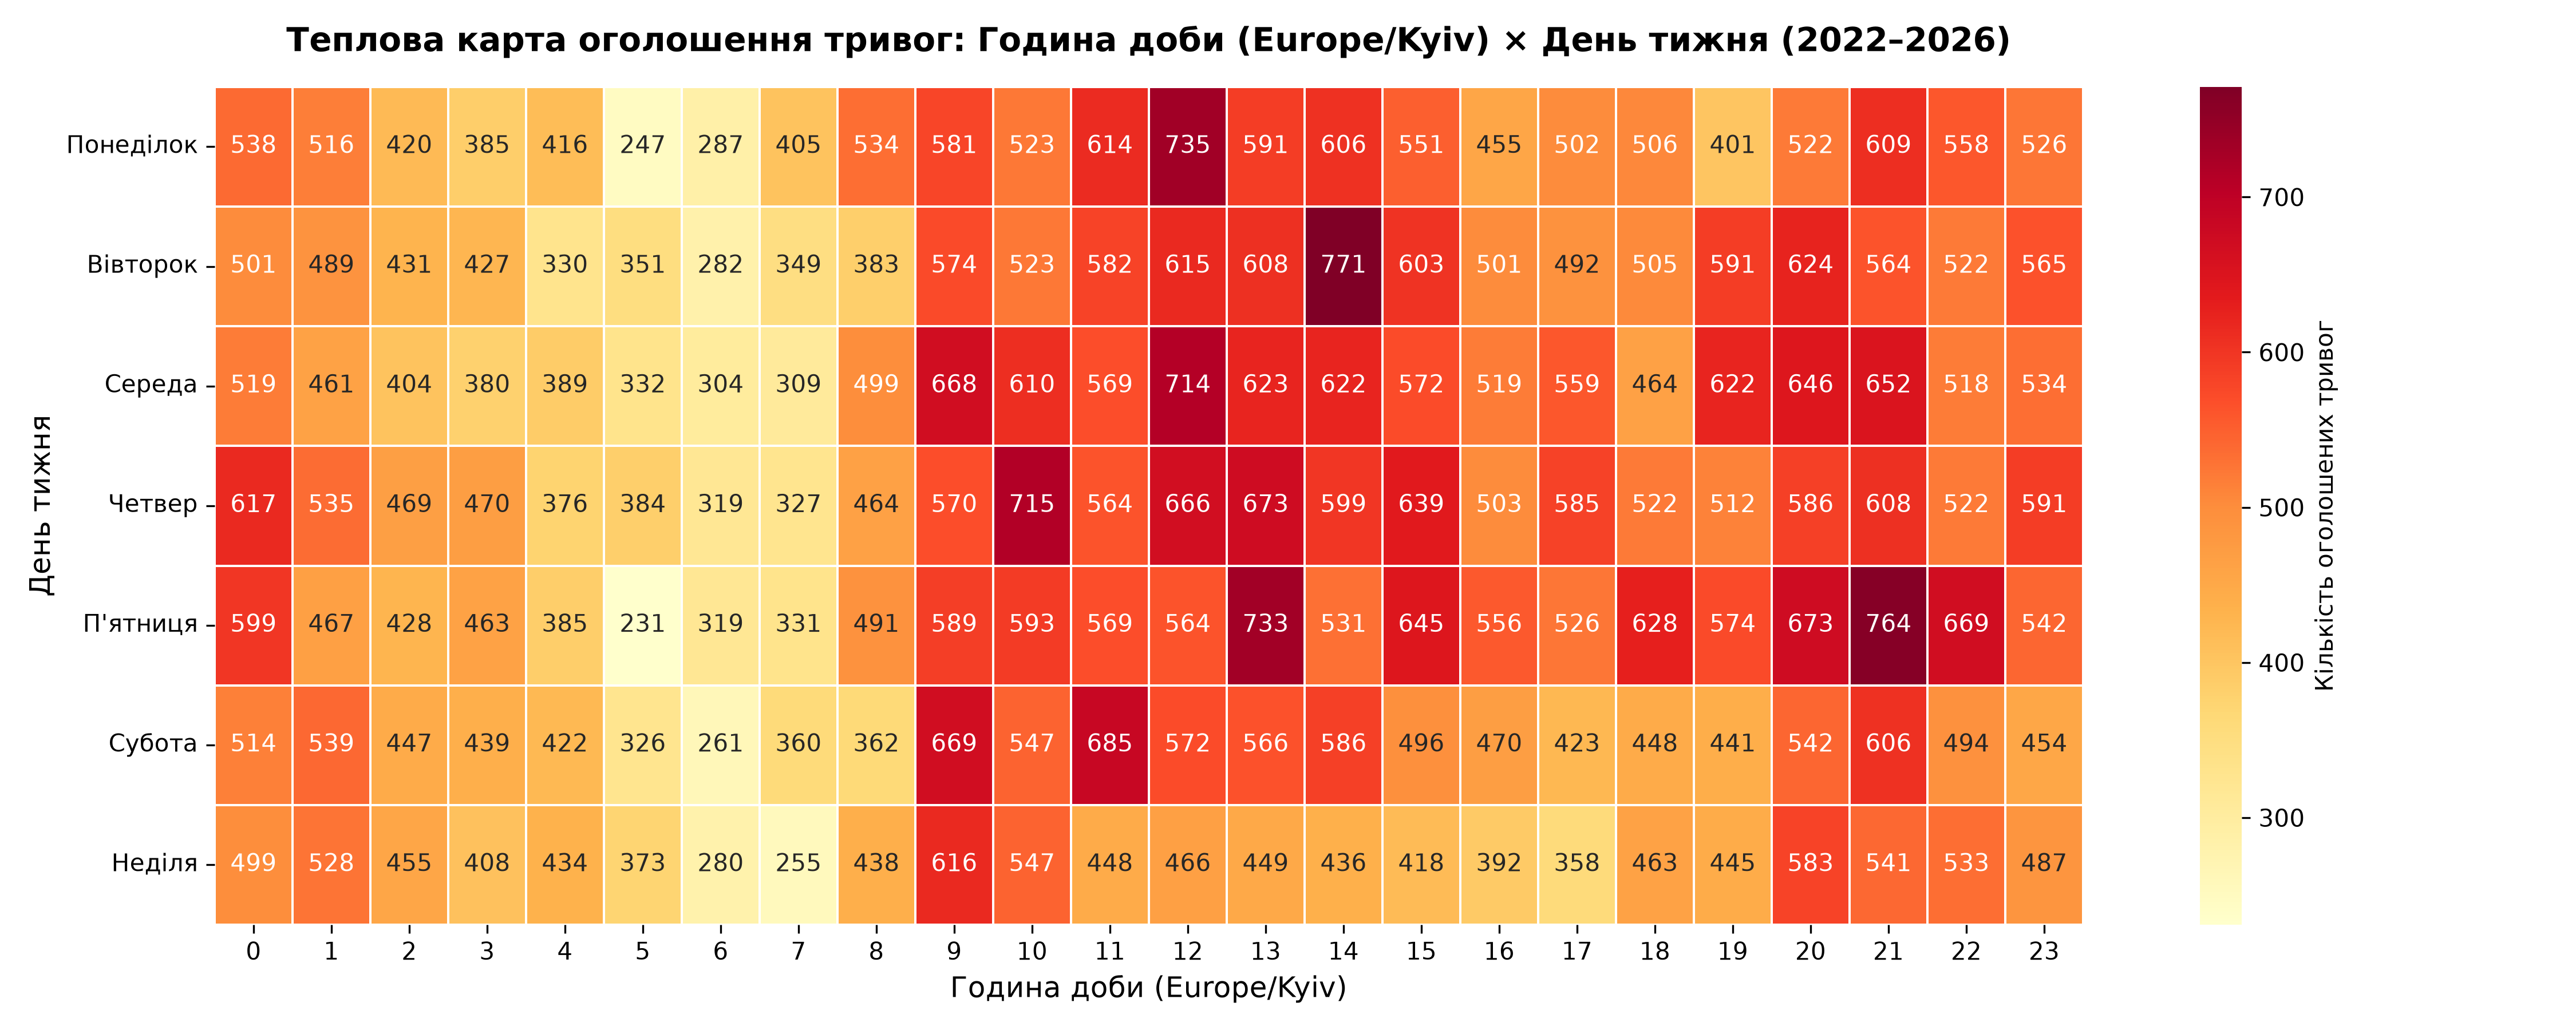

In [4]:
display(Image("../reports/figures/01_heatmap_24x7.png"))

## 4. Еволюція добового профілю тривог за роками (2022–2026)

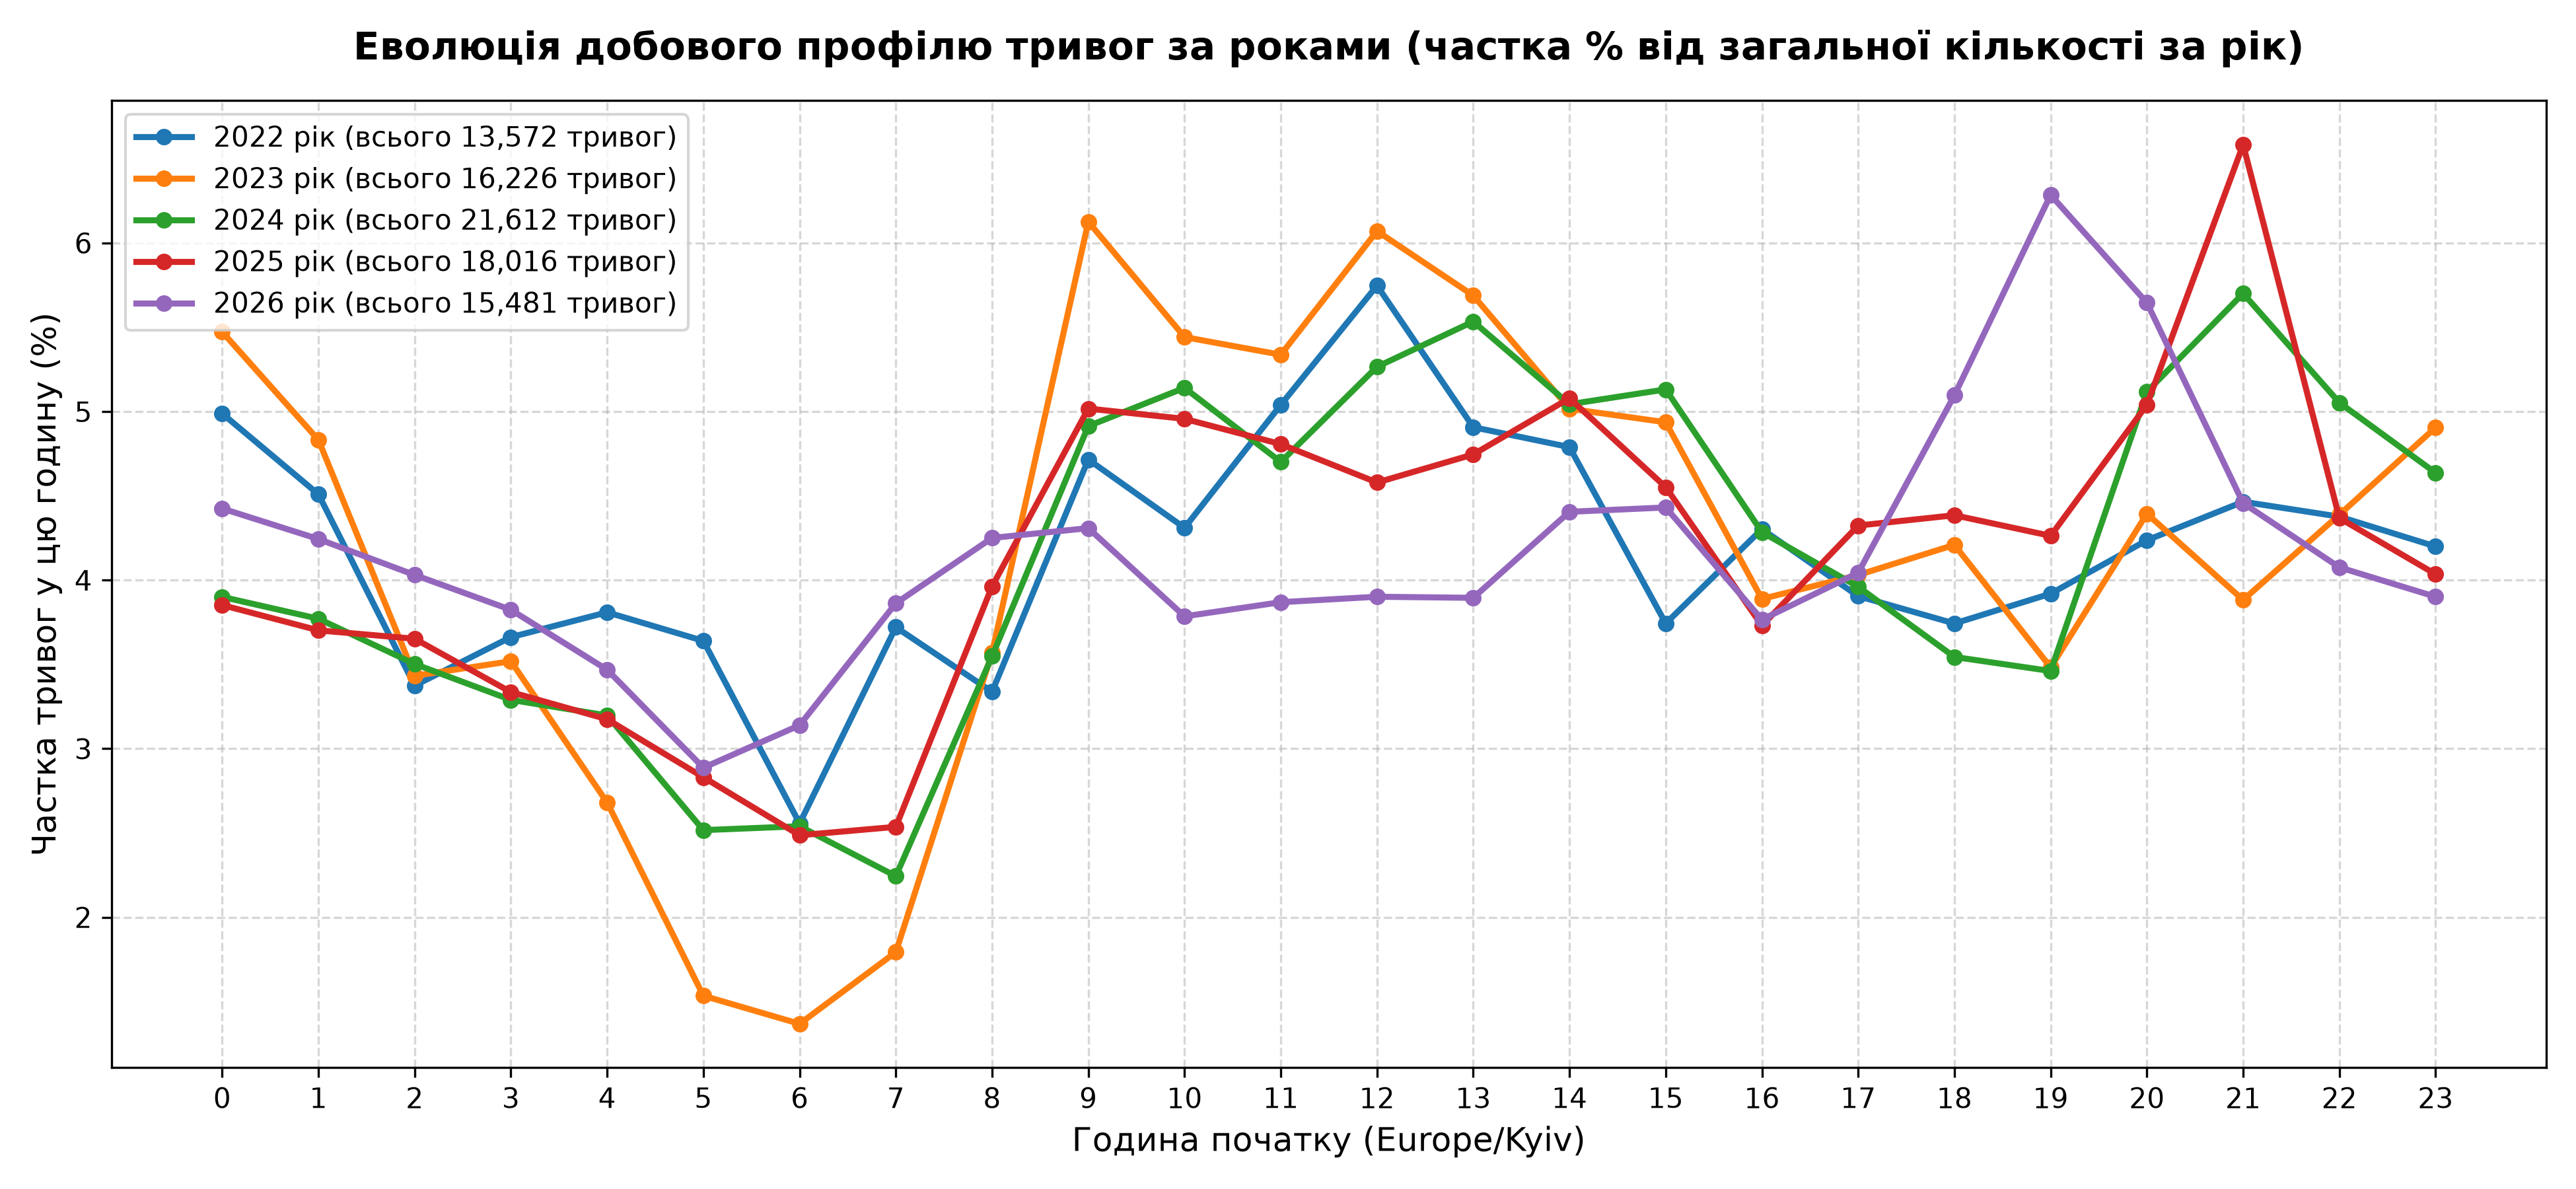

In [5]:
display(Image("../reports/figures/02_hourly_evolution_by_year.png"))

## 5. Розподіл тривалості тривог

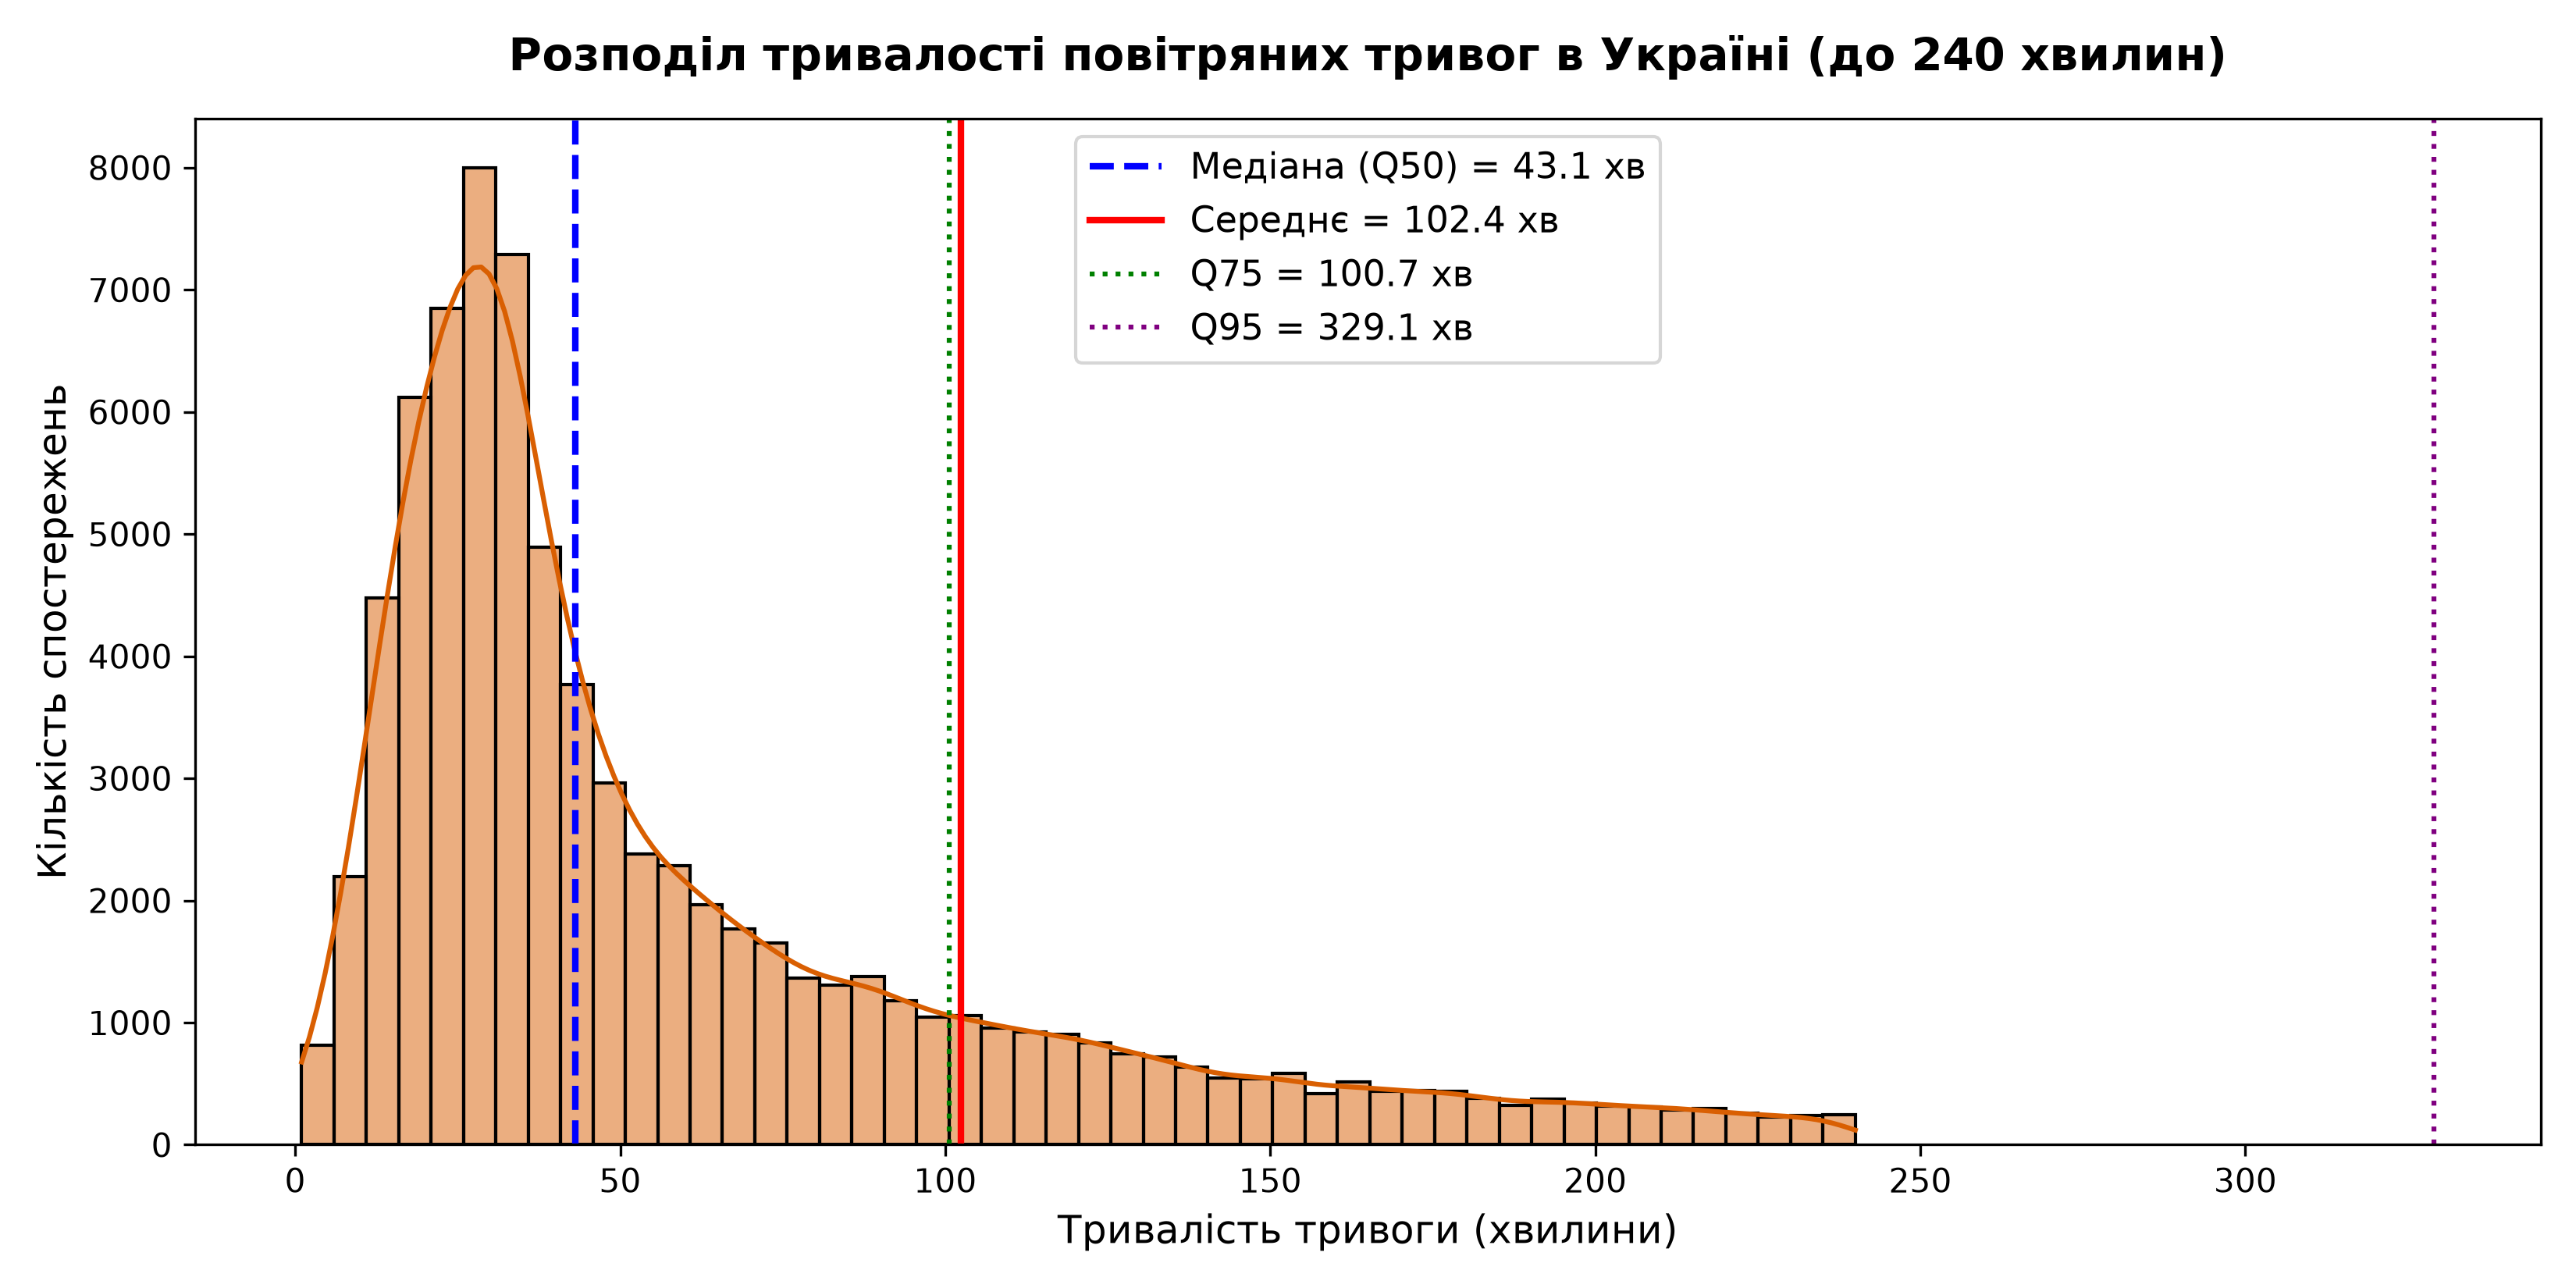

In [6]:
display(Image("../reports/figures/03_duration_distribution.png"))